# NESG: train and validation AUROC across ESM-2 layers

Open this notebook in Colab and choose **Run all**. A CPU runtime is sufficient;
no ESM or SAE inference is performed. Existing pooled activations are restored
from the private HF dataset. Full residue maps are not downloaded.

The notebook fits 33 standardized L2 logistic probes and a composition baseline,
using the frozen 2,361 training / 691 validation proteins and training-only
homology-aware folds. It displays both train-CV versus validation and train-fit
versus validation figures. The reserved test is not accessed.

**Reopening:** installed packages and valid cached files are reused. Complete
matching results on HF are downloaded instead of refitted. Partial fits resume
within the same runtime; deleting a runtime before final upload loses those
partial fits, but the saved ESM activations remain available.

**Execution status:** the workflow has local engineering tests; the actual 33-layer
results will appear when run with your Colab Secret `HF_TOKEN_PLM`. No placeholder
AUROC curves are included. HF remains the persistent result store; Drive supplies
code and the frozen local development manifest.

## 1. Locate the project and copy only changed inputs

Change `PROJECT_ROOT` only if your Drive project is in a different location.
No credential files, full-map tensors or reserved-test files are copied.

In [4]:
from pathlib import Path
import hashlib, json, os, shutil, subprocess, sys, venv
from google.colab import drive

if not Path('/content/drive/MyDrive').is_dir():
    drive.mount('/content/drive')
PROJECT_ROOT = Path('/content/drive/MyDrive/plm-property-interpretability')
source = PROJECT_ROOT / 'nesg_primary/esm_layer_probing'
work = Path('/content/nesg_esm_stage1')
required = [
    'common.py', 'extract.py', 'hf_storage.py', 'save_full_maps.py',
    'probe.py', 'plot_train_validation.py', 'run_layerwise_auroc.py',
    'protocol.json', 'data/extraction_manifest.tsv',
    'data/input_integrity.json', 'data/local_labels.tsv',
]
missing = [name for name in required if not (source / name).is_file()]
if missing:
    raise FileNotFoundError(f'Check PROJECT_ROOT and Drive sync. Missing: {missing}')
changed = 0
for name in required:
    src, dst = source / name, work / name
    dst.parent.mkdir(parents=True, exist_ok=True)
    digest = hashlib.sha256(src.read_bytes()).digest()
    if not dst.is_file() or hashlib.sha256(dst.read_bytes()).digest() != digest:
        shutil.copyfile(src, dst)
        changed += 1
    assert hashlib.sha256(dst.read_bytes()).digest() == digest
os.chdir(work)
print(f'Updated {changed} code/input files; unchanged files reused.')

Updated 0 code/input files; unchanged files reused.


## 2. Prepare or reuse the CPU probing environment

Reuse the extraction interpreter if it still exists. Otherwise create a small
separate environment inheriting Colab's numerical stack. Only missing probing
packages are installed as prebuilt wheels; there is no CUDA preflight, ESM
download or PyTorch installation. Package versions are recorded in the results.

In [5]:
import shlex
from IPython.utils.process import system

os.environ.update(USE_TORCH='1', USE_TF='0', USE_FLAX='0', PYTHONNOUSERSITE='1', MPLBACKEND='Agg')
EXTRACTION_PYTHON = Path('/content/nesg_esm_env/bin/python')
if not EXTRACTION_PYTHON.is_file():
    environment = Path('/content/nesg_probe_env')
    EXTRACTION_PYTHON = environment / 'bin/python'
    if not EXTRACTION_PYTHON.is_file():
        venv.EnvBuilder(system_site_packages=True, with_pip=False).create(environment)

def run_stage1(*arguments):
    status = system(shlex.join([str(EXTRACTION_PYTHON), '-u', *map(str, arguments)]))
    if status != 0:
        raise RuntimeError(f'Command stopped (exit {status}). See the output above.')

run_stage1('run_layerwise_auroc.py', '--setup-only')

Probing packages already installed; skipping pip.
CPU probing environment ready; no model weights or activations loaded.


## 3. Authenticate and restore the pooled cache

Enable notebook access to `HF_TOKEN_PLM` in Colab Secrets. The configured dataset
must already exist and be private. No repository is created. A complete valid
local cache skips downloads; a new runtime retrieves only the pooled arrays
(about 516 MB before compression), not the roughly 63.5 GB residue maps.

In [6]:
from google.colab import userdata
try:
    secret = userdata.get('HF_TOKEN_PLM')
except Exception:
    raise RuntimeError('Enable notebook access to HF_TOKEN_PLM in Colab Secrets.') from None
if not secret:
    raise RuntimeError('HF_TOKEN_PLM is missing from Colab Secrets.')
os.environ['HF_TOKEN_PLM'] = secret
del secret
DESTINATION_REPO = 'PLM-Interp/nesg-esm2-layerwise'
OUTPUT = Path('/content/nesg_esm_stage1_scratch/activations')
OUTPUT.mkdir(parents=True, exist_ok=True)
run_stage1('hf_storage.py', 'restore', '--repo', DESTINATION_REPO, '--folder', OUTPUT)
assert (OUTPUT / 'completed.json').is_file(), 'The complete pooled extraction must be available in HF.'

completed.json: 8.95kB [00:00, 25.8MB/s]
shard_0000.json: 100%|██████████████████████████| 148/148 [00:00<00:00, 967kB/s]
esm_stage1/shard_0000.npz: 100%|███████████| 10.8M/10.8M [00:00<00:00, 11.5MB/s]
shard_0001.json: 100%|██████████████████████████| 148/148 [00:00<00:00, 831kB/s]
esm_stage1/shard_0001.npz: 100%|███████████| 10.8M/10.8M [00:00<00:00, 18.1MB/s]
shard_0002.json: 100%|██████████████████████████| 148/148 [00:00<00:00, 762kB/s]
esm_stage1/shard_0002.npz: 100%|███████████| 10.8M/10.8M [00:00<00:00, 20.2MB/s]
shard_0003.json: 100%|██████████████████████████| 148/148 [00:00<00:00, 692kB/s]
esm_stage1/shard_0003.npz: 100%|███████████| 10.8M/10.8M [00:00<00:00, 15.5MB/s]
shard_0004.json: 100%|██████████████████████████| 148/148 [00:00<00:00, 728kB/s]
esm_stage1/shard_0004.npz: 100%|███████████| 10.8M/10.8M [00:00<00:00, 17.8MB/s]
shard_0005.json: 100%|██████████████████████████| 148/148 [00:00<00:00, 869kB/s]
esm_stage1/shard_0005.npz: 100%|███████████| 10.8M/10.8M [00:00<00:0

## 4. Verify the development population

IDs, original sequences and hashes are checked against the frozen inputs.
Training/validation homology groups must be disjoint. Displayed counts are
calculated from the local development manifest; no test records are loaded.

In [7]:
verify_inputs = (
    "import pandas as pd; from common import read_local; d=read_local(); "
    "assert d.split.value_counts().to_dict()=={'train':2361,'validation':691}; "
    "assert set(d.loc[d.split=='train','audit_cluster']).isdisjoint(set(d.loc[d.split=='validation','audit_cluster'])); "
    "print(pd.crosstab(d.split,d.label).rename(columns={0:'Insoluble',1:'Soluble'}).to_string()); "
    "print('Frozen sequence hashes and homology separation verified.')"
)
run_stage1('-c', verify_inputs)

label       Insoluble  Soluble
split                         
train             716     1645
validation        200      491
Frozen sequence hashes and homology separation verified.


## 5. Fit or reuse the 33 layer probes

Each layer uses the same 1,280-dimensional mean-pooled representation and
StandardScaler → L2 logistic regression pipeline. Scaling is learned inside
each training fold. C is chosen by mean AUROC over the five frozen homology
folds from `[0.0001, 0.001, 0.01, 0.1, 1, 10]`, then the final probe is refitted
on all training proteins. Validation is never used to tune C or fit a model.

The diagnostic composition baseline uses the 20 standard amino-acid fractions
plus log length. X residues are retained without substitution. There is no
class/family balancing. Validation uncertainty uses 2,000 homology-group
bootstrap resamples shared across layers.

Completed results are saved to private HF. Per-protein experimental labels
remain in the separate local manifest and are omitted from published prediction
tables. Fitted probes, coefficients, scores, plots and provenance are retained.

In [8]:
run_stage1(
    'run_layerwise_auroc.py',
    '--activations', OUTPUT,
    '--repo', DESTINATION_REPO,
    '--threads', '2',
)
latest = json.loads(Path('/content/nesg_layerwise_probes/latest.json').read_text())
results = Path(latest['results'])
print('Verified result directory:', results)

Probing packages already installed; skipping pip.
Fitting composition baseline with frozen training CV
Fitting layer 1/33
Fitting layer 2/33
Fitting layer 3/33
Fitting layer 4/33
Fitting layer 5/33
Fitting layer 6/33
Fitting layer 7/33
Fitting layer 8/33
Fitting layer 9/33
Fitting layer 10/33
Fitting layer 11/33
Fitting layer 12/33
Fitting layer 13/33
Fitting layer 14/33
Fitting layer 15/33
Fitting layer 16/33
Fitting layer 17/33
Fitting layer 18/33
Fitting layer 19/33
Fitting layer 20/33
Fitting layer 21/33
Fitting layer 22/33
Fitting layer 23/33
Fitting layer 24/33
Fitting layer 25/33
Fitting layer 26/33
Fitting layer 27/33
Fitting layer 28/33
Fitting layer 29/33
Fitting layer 30/33
Fitting layer 31/33
Fitting layer 32/33
Fitting layer 33/33
      model  layer     C  training_n  training_fit_auroc  training_oof_auroc  validation_n    auroc  average_precision  auroc_low  auroc_high   ap_low  ap_high  cv_mean    cv_sd   cv_min   cv_max  bootstrap_valid  delta_vs_composition  delta_low 

## 6. Training cross-validation versus fixed validation

The train curve averages five held-out-fold AUROCs; its band is **±1 fold SD**.
The validation curve uses the final model; its band is a **95% homology-group
bootstrap CI**. These bands have different meanings. The same training folds
select C, so train-CV scores are tuning estimates, not unbiased nested-CV results.

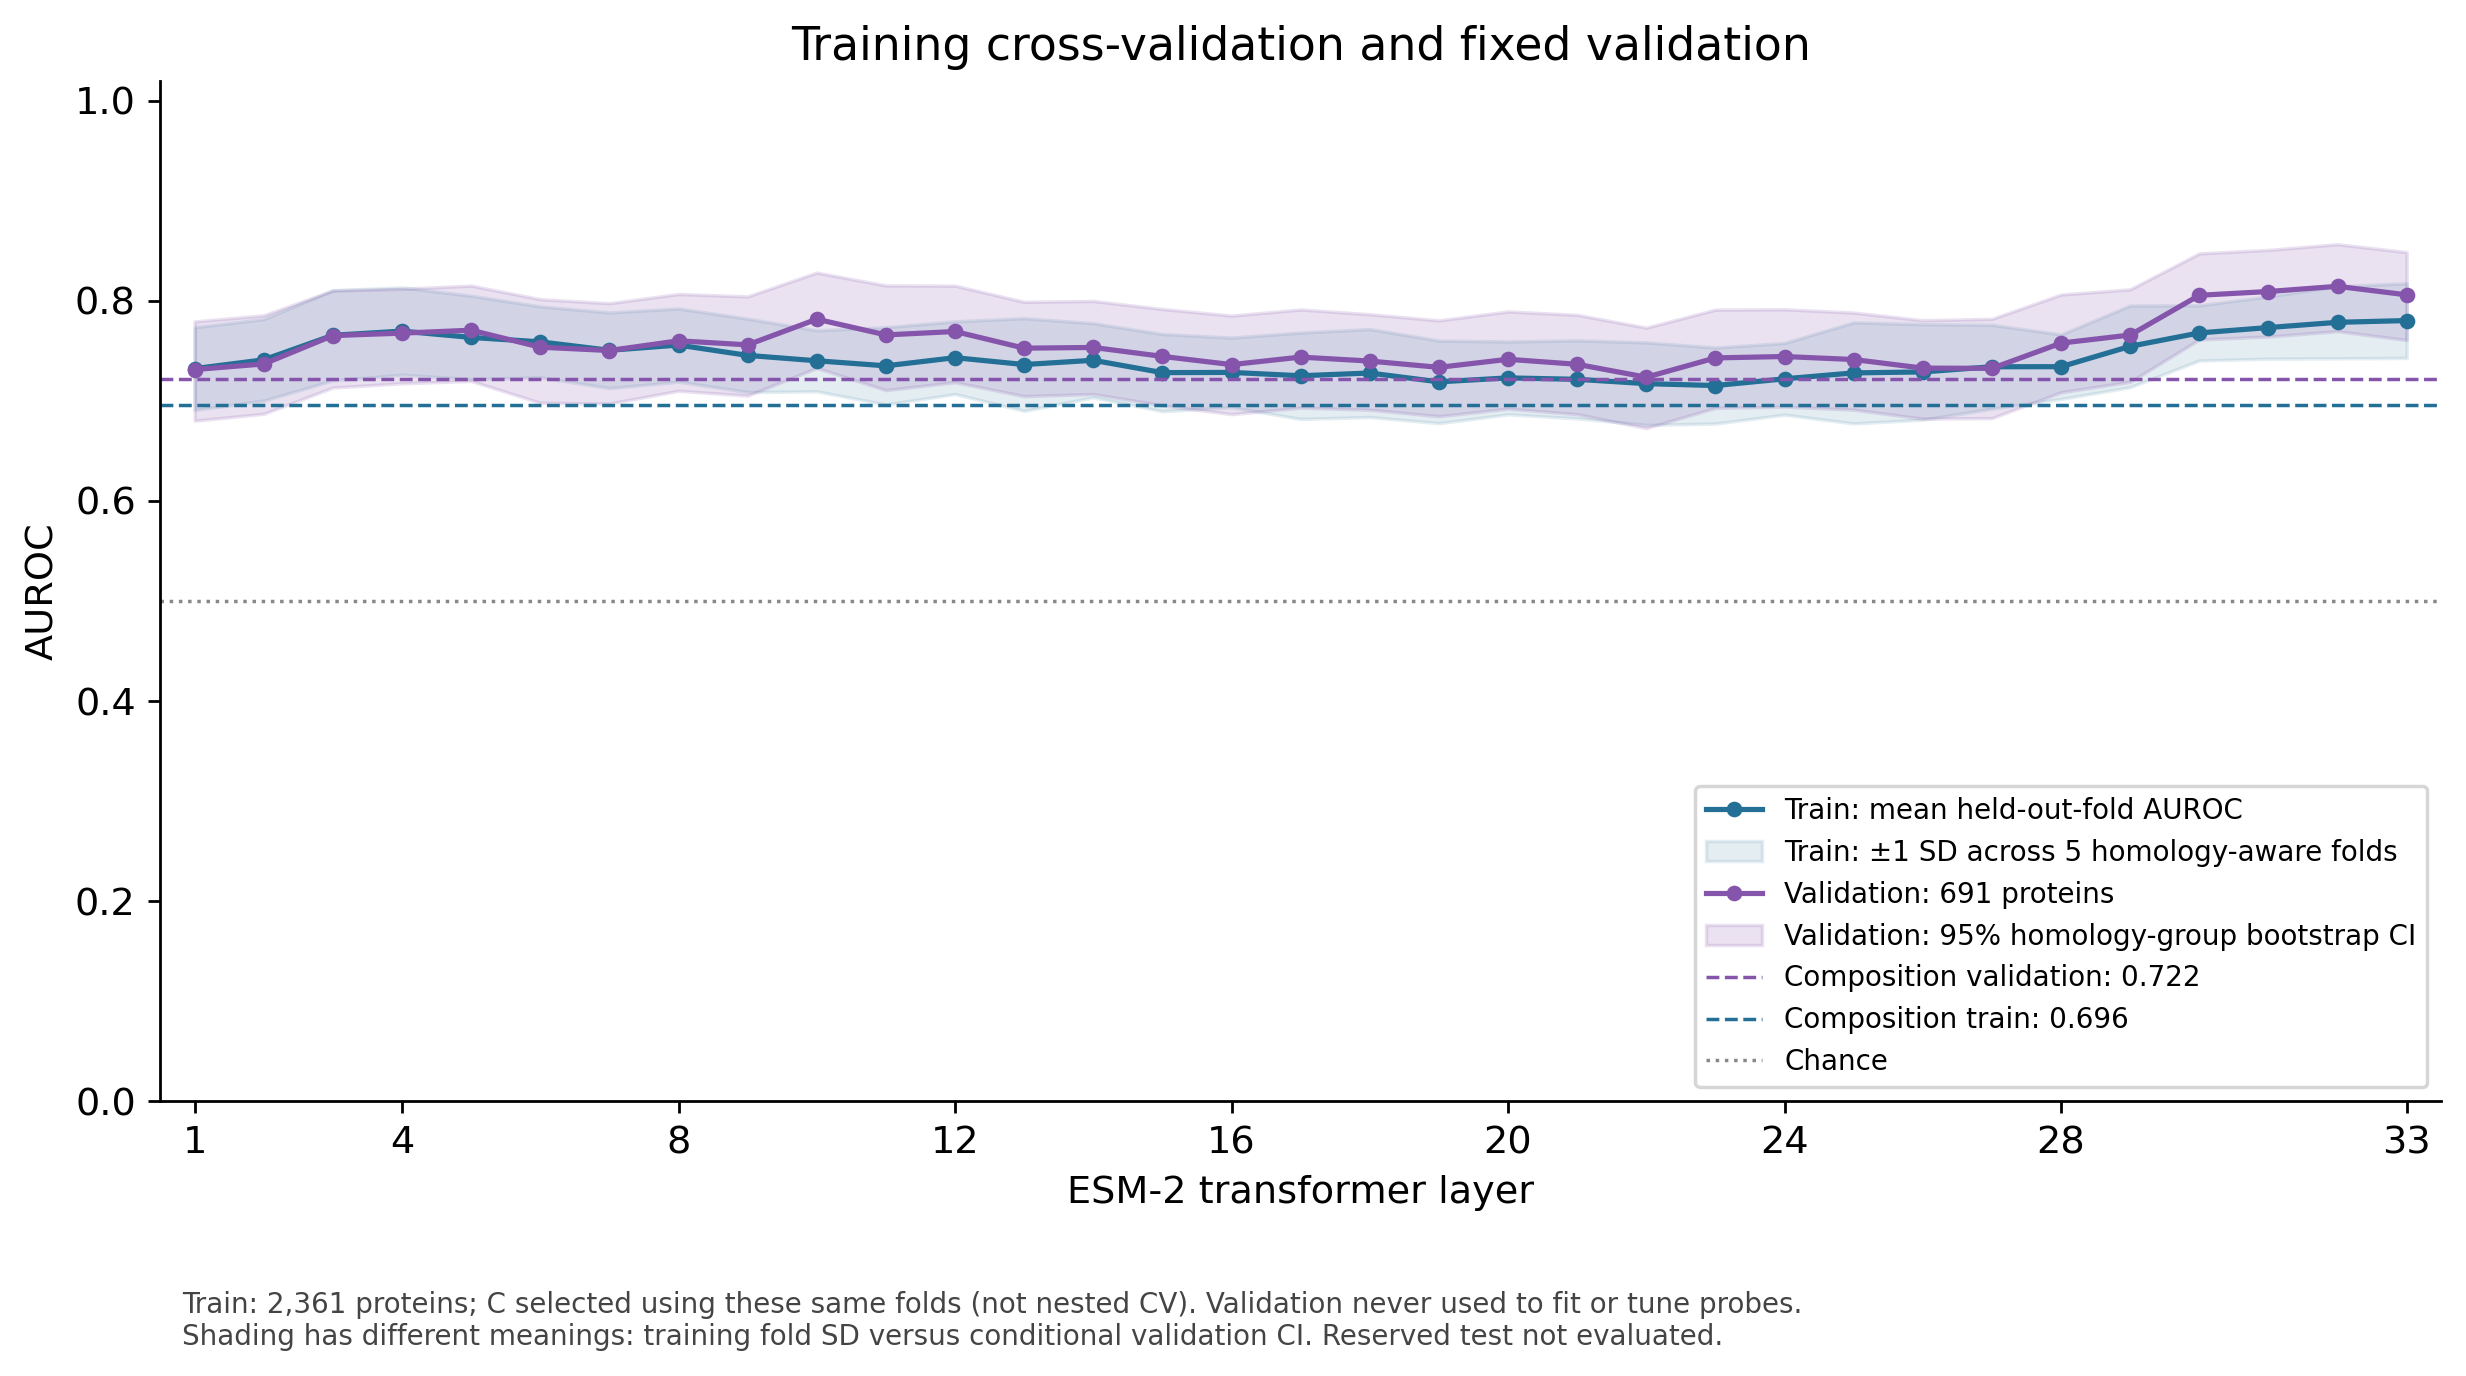

In [9]:
from IPython.display import Image, Markdown, display
display(Image(filename=str(results / 'figures/train_validation_auroc.png')))

## 7. Training fit versus validation: overfitting diagnostic

Here training AUROC is measured on the proteins used to fit the final probe.
It is explicitly **in-sample** and can be optimistic. Use the previous figure
for held-out-fold training estimates. A gap can reflect overfitting and
differences between populations; it is not a causal diagnosis.

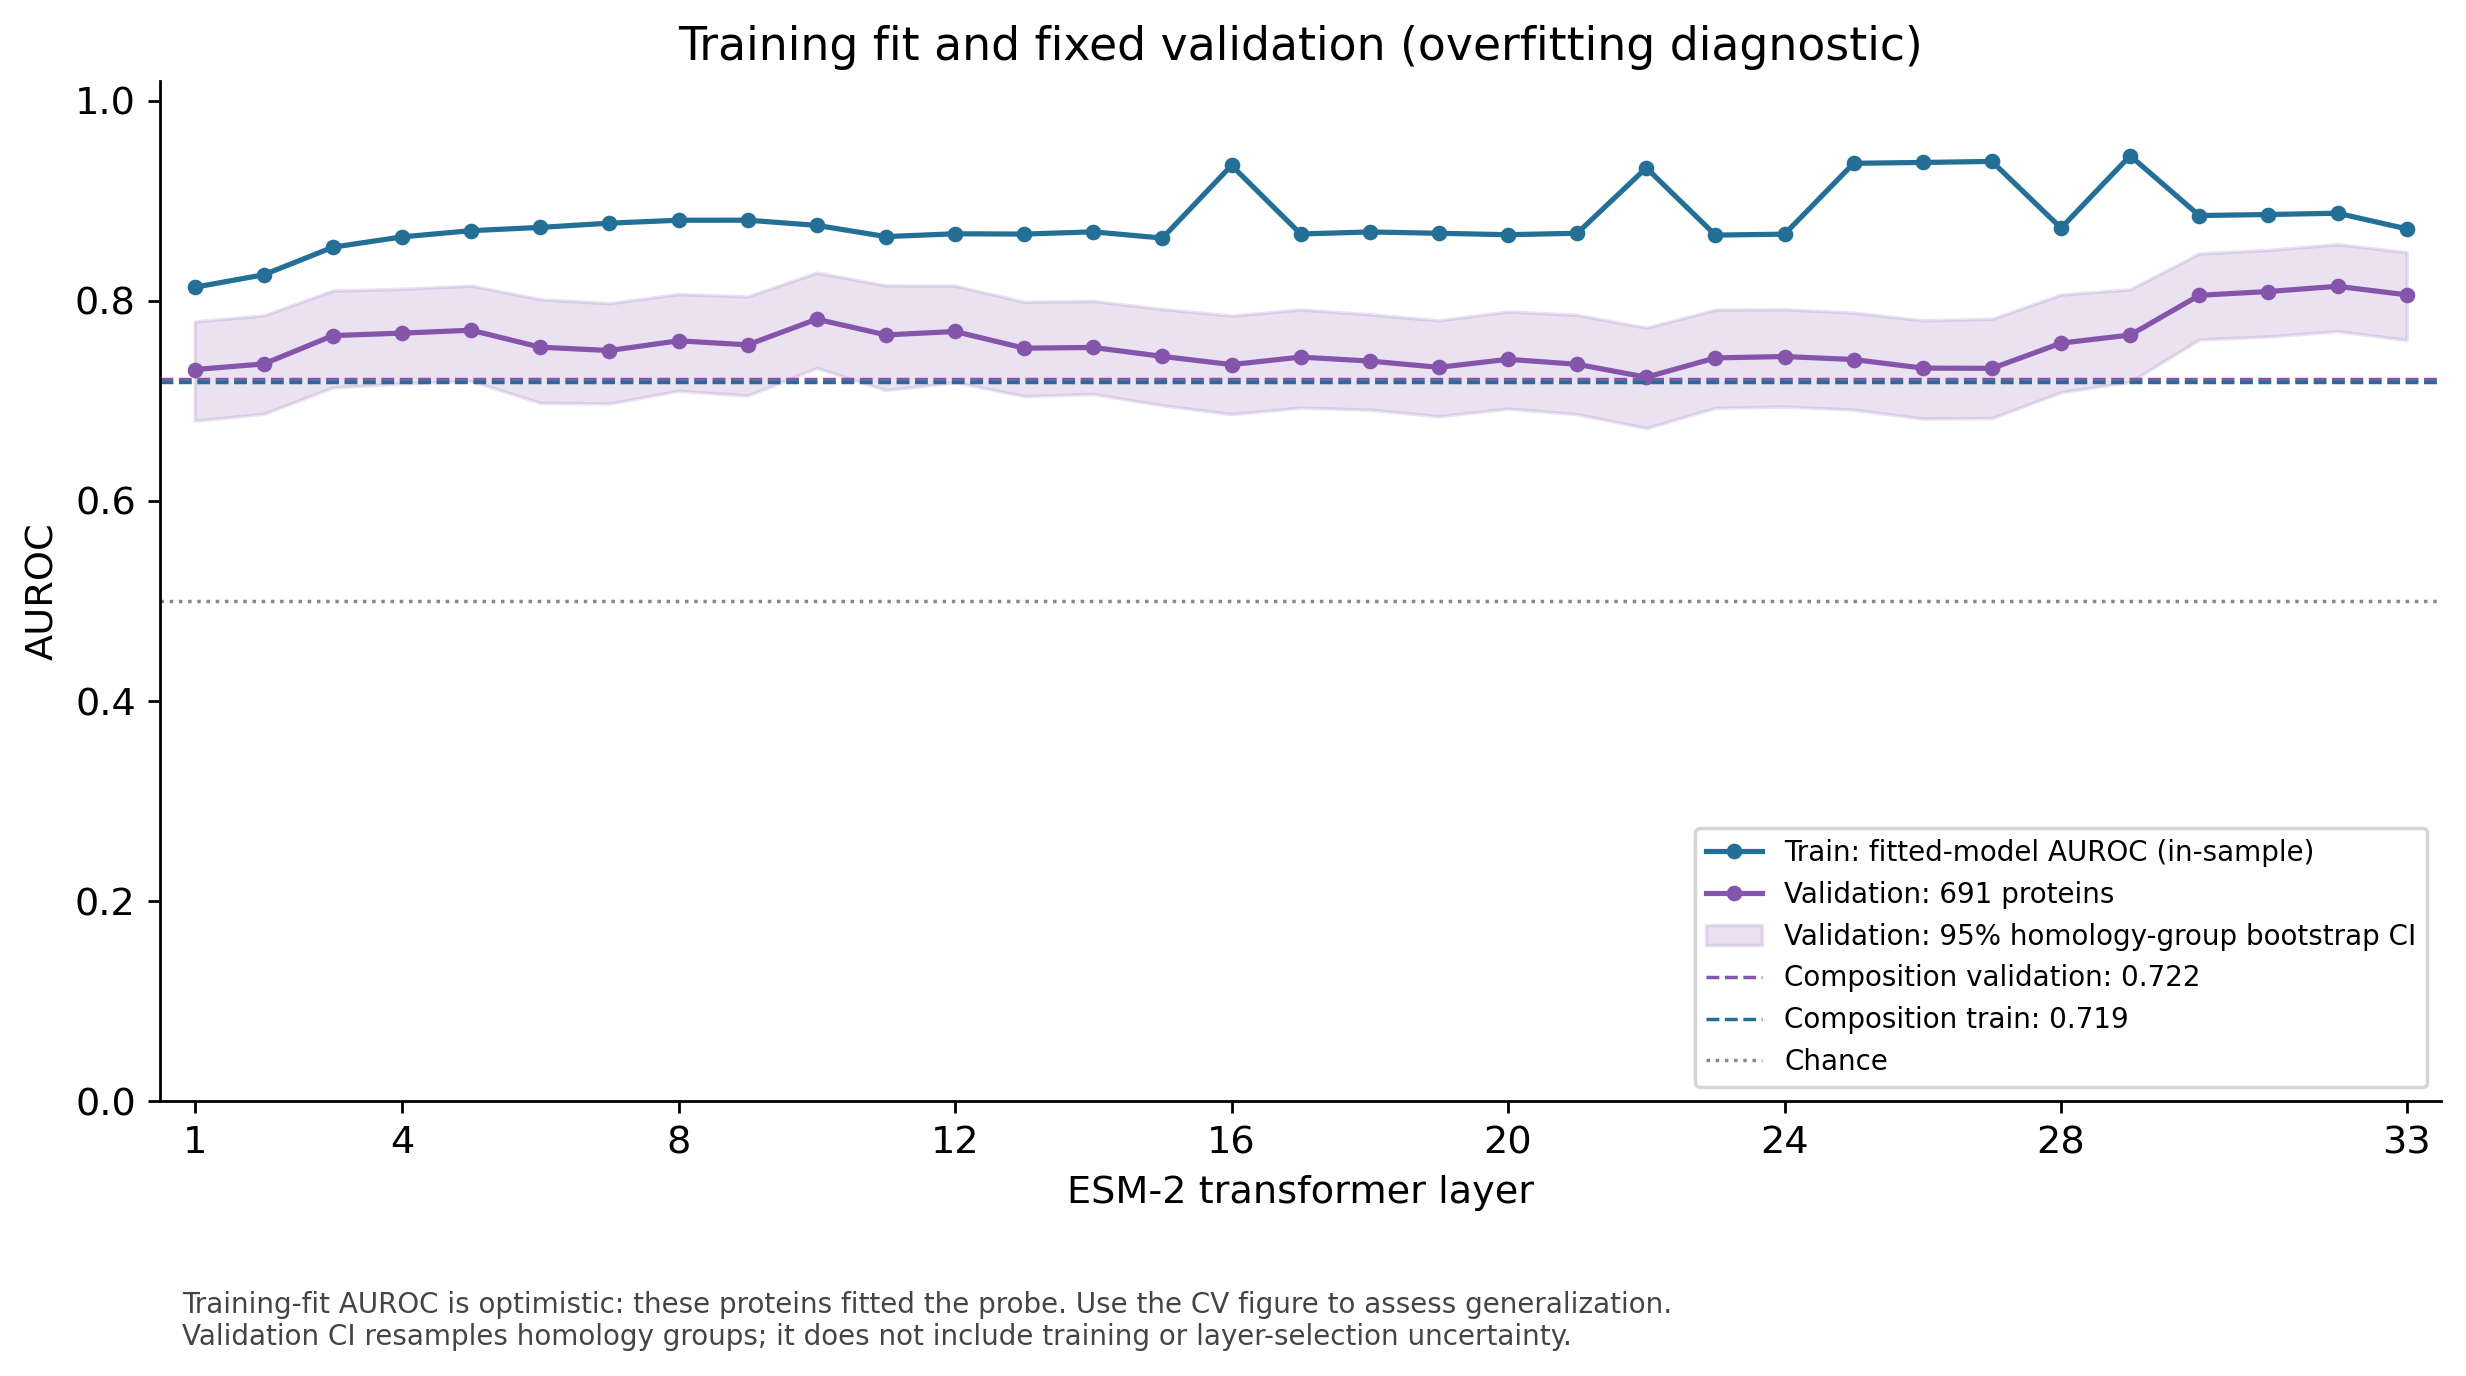

In [10]:
display(Image(filename=str(results / 'figures/train_fit_validation_auroc.png')))

## 8. Exact values, interpretation and saved outputs

The largest validation AUROC is descriptive across 33 inspected layers;
pointwise intervals do not correct for that selection. Layer-wise decoding
does not establish direct versus indirect encoding or a causal computation.
No SAE discovery, intervention or test evaluation is performed here.

In [11]:
import csv
display(Markdown((results / 'TRAIN_VALIDATION_AUROC.md').read_text()))
with (results / 'train_validation_auroc.tsv').open() as handle:
    rows = list(csv.DictReader(handle, delimiter='\t'))
lines = ['| Layer | Train CV | Train fit | Validation | Validation 95% CI |',
         '|---:|---:|---:|---:|---:|']
for row in rows:
    lines.append(
        f"| {row['layer']} | {float(row['cv_mean']):.4f} | {float(row['training_fit_auroc']):.4f} | "
        f"{float(row['auroc']):.4f} | {float(row['auroc_low']):.4f}–{float(row['auroc_high']):.4f} |"
    )
display(Markdown('\n'.join(lines)))
url = f"https://huggingface.co/datasets/{latest['repository']}/tree/main/{latest['hf_prefix']}"
display(Markdown(f'[Open private HF results]({url}) — download `results.zip` for PNG/SVG figures, exact tables and fitted probes.'))
print('Plots are embedded above. No activations were recomputed.')

# NESG layer-wise solubility AUROC

All 33 frozen ESM-2 layer probes completed. Training: 2,361; validation: 691; reserved test not evaluated.

Highest observed validation AUROC: layer 32, 0.8146 (group-bootstrap 95% CI 0.7697–0.8567). This is a descriptive maximum across 33 layers, not an independently confirmed best layer.

Composition baseline: train CV 0.6961 ± 0.0456 fold SD; validation 0.7216.

Layer-wise train CV AUROC range: 0.7154–0.7804; validation range: 0.7237–0.8146.

The main train curve averages the five held-out-fold AUROCs at training-selected C. Because those folds also select C, these are tuning estimates, not unbiased nested-CV estimates. Pooled OOF AUROC is included in the table, but can be affected by fold-to-fold score calibration. The second figure shows explicitly in-sample training fit as an overfitting diagnostic. Natural class/family distributions and frozen splits are preserved. AUROC establishes linear decodability, not direct encoding or causality.


| Layer | Train CV | Train fit | Validation | Validation 95% CI |
|---:|---:|---:|---:|---:|
| 1 | 0.7323 | 0.8136 | 0.7314 | 0.6803–0.7795 |
| 2 | 0.7411 | 0.8261 | 0.7370 | 0.6872–0.7856 |
| 3 | 0.7656 | 0.8537 | 0.7653 | 0.7134–0.8104 |
| 4 | 0.7698 | 0.8640 | 0.7678 | 0.7177–0.8121 |
| 5 | 0.7635 | 0.8702 | 0.7707 | 0.7200–0.8153 |
| 6 | 0.7591 | 0.8735 | 0.7537 | 0.6981–0.8017 |
| 7 | 0.7506 | 0.8777 | 0.7504 | 0.6974–0.7977 |
| 8 | 0.7558 | 0.8806 | 0.7601 | 0.7102–0.8069 |
| 9 | 0.7455 | 0.8807 | 0.7561 | 0.7053–0.8045 |
| 10 | 0.7402 | 0.8755 | 0.7817 | 0.7330–0.8283 |
| 11 | 0.7351 | 0.8643 | 0.7660 | 0.7108–0.8155 |
| 12 | 0.7432 | 0.8671 | 0.7694 | 0.7188–0.8153 |
| 13 | 0.7364 | 0.8668 | 0.7527 | 0.7048–0.7991 |
| 14 | 0.7406 | 0.8690 | 0.7535 | 0.7069–0.8000 |
| 15 | 0.7283 | 0.8628 | 0.7445 | 0.6956–0.7919 |
| 16 | 0.7285 | 0.9354 | 0.7363 | 0.6868–0.7853 |
| 17 | 0.7252 | 0.8669 | 0.7438 | 0.6933–0.7914 |
| 18 | 0.7279 | 0.8689 | 0.7399 | 0.6912–0.7867 |
| 19 | 0.7191 | 0.8676 | 0.7336 | 0.6847–0.7805 |
| 20 | 0.7231 | 0.8662 | 0.7416 | 0.6923–0.7895 |
| 21 | 0.7216 | 0.8676 | 0.7366 | 0.6868–0.7861 |
| 22 | 0.7173 | 0.9330 | 0.7237 | 0.6729–0.7733 |
| 23 | 0.7154 | 0.8658 | 0.7430 | 0.6931–0.7913 |
| 24 | 0.7221 | 0.8667 | 0.7444 | 0.6943–0.7916 |
| 25 | 0.7280 | 0.9376 | 0.7414 | 0.6913–0.7884 |
| 26 | 0.7290 | 0.9384 | 0.7328 | 0.6823–0.7806 |
| 27 | 0.7342 | 0.9394 | 0.7326 | 0.6829–0.7820 |
| 28 | 0.7342 | 0.8728 | 0.7578 | 0.7087–0.8064 |
| 29 | 0.7546 | 0.9451 | 0.7659 | 0.7192–0.8116 |
| 30 | 0.7680 | 0.8854 | 0.8056 | 0.7615–0.8475 |
| 31 | 0.7734 | 0.8864 | 0.8094 | 0.7644–0.8510 |
| 32 | 0.7786 | 0.8877 | 0.8146 | 0.7697–0.8567 |
| 33 | 0.7804 | 0.8720 | 0.8061 | 0.7609–0.8488 |

[Open private HF results](https://huggingface.co/datasets/PLM-Interp/nesg-esm2-layerwise/tree/main/esm_stage1/layerwise_probing_v1/19424161967de07ab75b014ab6a06b77be041677212076ecb4d08f28382c755b) — download `results.zip` for PNG/SVG figures, exact tables and fitted probes.

Plots are embedded above. No activations were recomputed.
